# Part IV — k-means: the three families of cars
**Method (sessions 10–11):** k-means clustering, elbow plot and silhouette score.
**Why:** the professor noted that *"some teams simply have better cars"*. On the PCA map, cars form groups. k-means finds them automatically, and the group becomes a feature: **top car / midfield car / back-of-grid car**.

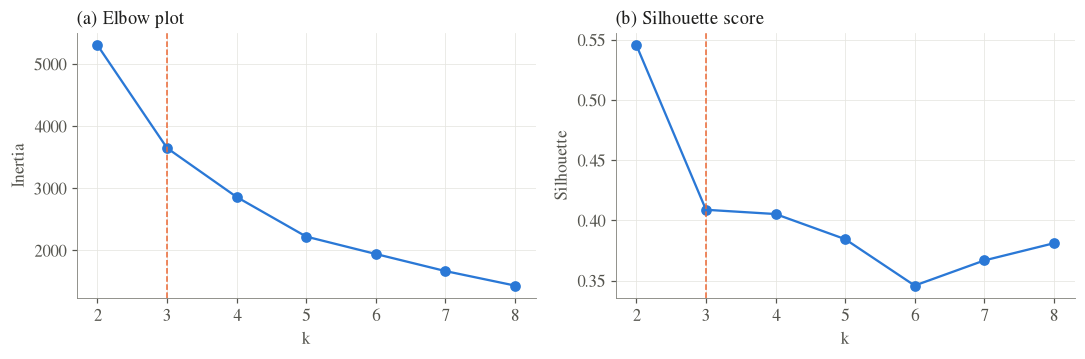

k,2,3,4,5,6,7,8
inertia,5302.000,3647.000,2860.000,2222.000,1942.000,1667.000,1434.000
silhouette,0.545,0.409,0.405,0.384,0.346,0.367,0.381


In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
from f1duel.model import CarProfile
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
train = d[d.year <= 2024]
prof = CarProfile().fit(train)
Z = prof._z(train.drop_duplicates(['raceId', 'team']))
ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=20, random_state=2026).fit(Z); inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ks, inertia, 'o-', color=BLUE); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia'); title(ax[0], '(a) Elbow plot')
ax[1].plot(ks, sil, 'o-', color=BLUE); ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette'); title(ax[1], '(b) Silhouette score')
for a in ax: a.axvline(3, color=ORANGE, ls='--', lw=1)
fig.tight_layout(); save(fig, '04_choose_k'); plt.show()
pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia), 'silhouette': np.round(sil, 3)}).set_index('k').T

**Choice: k = 3.** The elbow bends at 3. The silhouette is highest at k = 2 (it only splits "top" from "the rest"), but k = 3 keeps a similar score and gives the three groups every F1 fan recognises. We choose meaning plus a good score, and say so.

In [2]:
dd = prof.transform(d)
summary = dd.groupby('tier').agg(starts=('top10', 'size'), scored=('top10', 'mean'), podium=('podium', 'mean'),
                                 avg_grid=('grid', 'mean'), car_perf=('car_perf', 'mean'))
summary.index = ['Top car', 'Midfield car', 'Back-of-grid car']; summary.round(2)

,starts,scored,podium,avg_grid,car_perf
Top car,1453,0.84,0.46,5.16,3.17
Midfield car,1911,0.55,0.07,10.43,0.04
Back-of-grid car,2071,0.20,0.00,14.86,-2.18


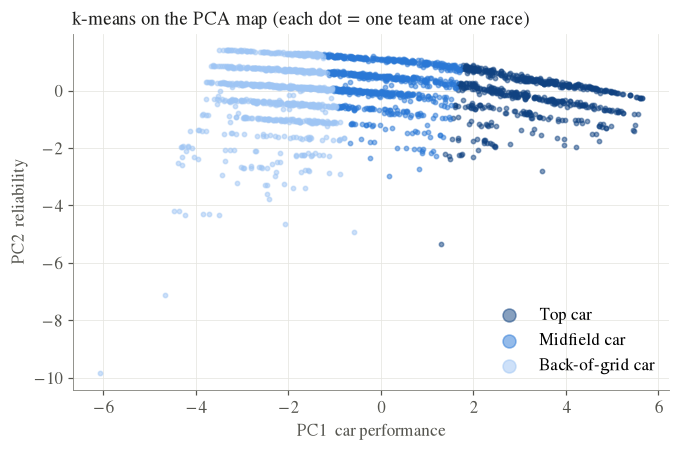

In [3]:
pts = dd[dd.year <= 2024].drop_duplicates(['raceId', 'team'])
fig, ax = plt.subplots(figsize=(7, 4.2))
for t, name in enumerate(['Top car', 'Midfield car', 'Back-of-grid car']):
    p = pts[pts.tier == t]; ax.scatter(p.car_perf, p.car_rel, s=8, alpha=0.5, color=TIER_COLORS[t], label=name)
ax.set_xlabel('PC1  car performance'); ax.set_ylabel('PC2  reliability'); ax.legend(markerscale=3)
title(ax, 'k-means on the PCA map (each dot = one team at one race)'); save(fig, '04_clusters'); plt.show()

**Reading:** a top car scores points in about 84% of its starts, a midfield car in about 55%, a back-of-grid car in about 20%. In Part V, these groups help the model see a fast car stuck at the back of the grid.